# Assignment #3

Write a short report to explain the processes of enhancing the given four images.

1. Write programs to remove noise and enhance the given images. Which filters and what
sizes are suitable for each of the noisy image?

In [81]:
!uv add Pillow numpy matplotlib pandas opencv-python

Resolved 46 packages in 3ms
Checked 14 packages in 1ms


In [82]:
from matplotlib import pyplot as plt
import cv2

# load images
noisy_cabin1_1_img   = cv2.imread('assets/noisy_cabin1_1.jpg',  cv2.IMREAD_GRAYSCALE)
noisy_cabin1_2_img   = cv2.imread('assets/noisy_cabin1_2.jpg',  cv2.IMREAD_GRAYSCALE)
blurry_stop_sign_img = cv2.imread('assets/blury_stop_sign.jpg')
blurry_moon_img      = cv2.imread('assets/blurry_moon.jpeg' )

Text(0, 0.5, 'Frequency')

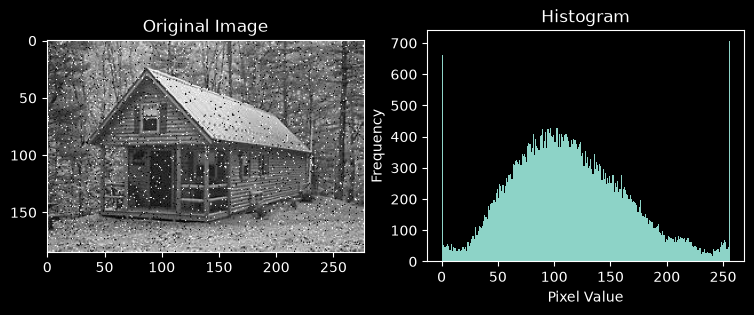

In [83]:
# The original image information
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 3))
plt.subplot(1, 2, 1)
plt.title('Original Image')
plt.imshow(noisy_cabin1_1_img, cmap='gray')
plt.subplot(1, 2, 2)
plt.title('Histogram')
plt.hist(noisy_cabin1_1_img.ravel(), bins=256, range=(0, 256))
plt.xlabel('Pixel Value')
plt.ylabel('Frequency')

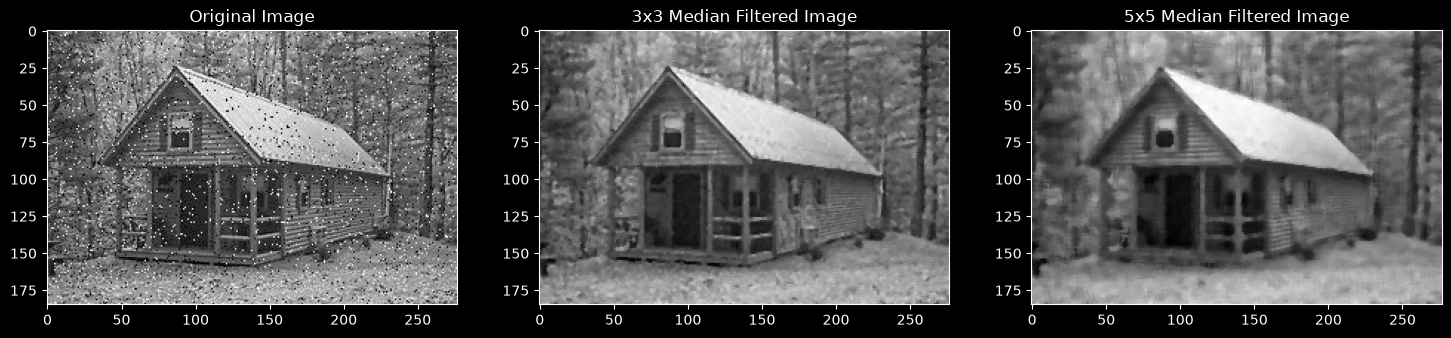

In [84]:
# noisy cabin1 loogs like it has salt and pepper noise, so we can use median filter to remove the noise

# Full algorithm for median filter:
# for x from edgex to image width - edgex do
    # for y from edgey to image height - edgey do
    #     i = 0
    #     for fx from 0 to window width do
    #         for fy from 0 to window height do
    #             window[i] := inputPixelValue[x + fx - edgex][y + fy - edgey]
    #             i := i + 1
    #     sort entries in window[]
    #     outputPixelValue[x][y] := window[window width * window height / 2]


plt.figure(figsize=(18, 4))

plt.subplot(1, 3, 1)
plt.title('Original Image')
plt.imshow(noisy_cabin1_1_img, cmap='gray')

plt.subplot(1, 3, 2)
plt.title('3x3 Median Filtered Image')
# Median filter with 3x3 window size
noisy_cabin1_1_img_filtered = cv2.medianBlur(noisy_cabin1_1_img, 3)
plt.imshow(noisy_cabin1_1_img_filtered, cmap='gray')

plt.subplot(1, 3, 3)
plt.title('5x5 Median Filtered Image')
# Median filter with 5x5 window size
noisy_cabin1_1_img_filtered = cv2.medianBlur(noisy_cabin1_1_img, 5)
plt.imshow(noisy_cabin1_1_img_filtered, cmap='gray')

จะเห็นว่าภาพไม่มี noise แบบ salt and pepper แล้ว แต่มีความเบลอเกิดขึ้นแทน ยิ่งเพิ่มขนาดของ kernel มากเท่าไหร่ ความเบลอก็จะมากขึ้นเท่านั้น ดังนั้นจึงควรเลือก kernel ที่มีขนาดเล็กที่สุดที่สามารถลด noise ได้ คือ 3x3 ก็เพียงพอแล้ว

Text(0, 0.5, 'Frequency')

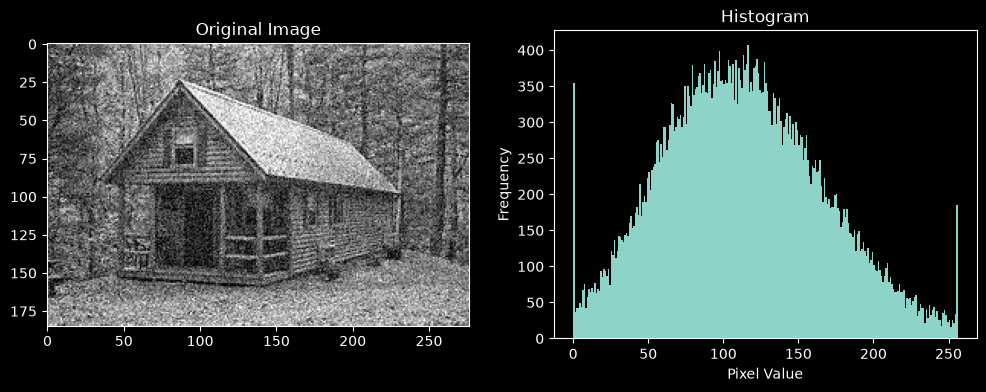

In [85]:
# ภาพที่ 2
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.title('Original Image')
plt.imshow(noisy_cabin1_2_img, cmap='gray')
plt.subplot(1, 2, 2)
plt.title('Histogram')
plt.hist(noisy_cabin1_2_img.ravel(), bins=256, range=(0, 256))
plt.xlabel('Pixel Value')
plt.ylabel('Frequency')

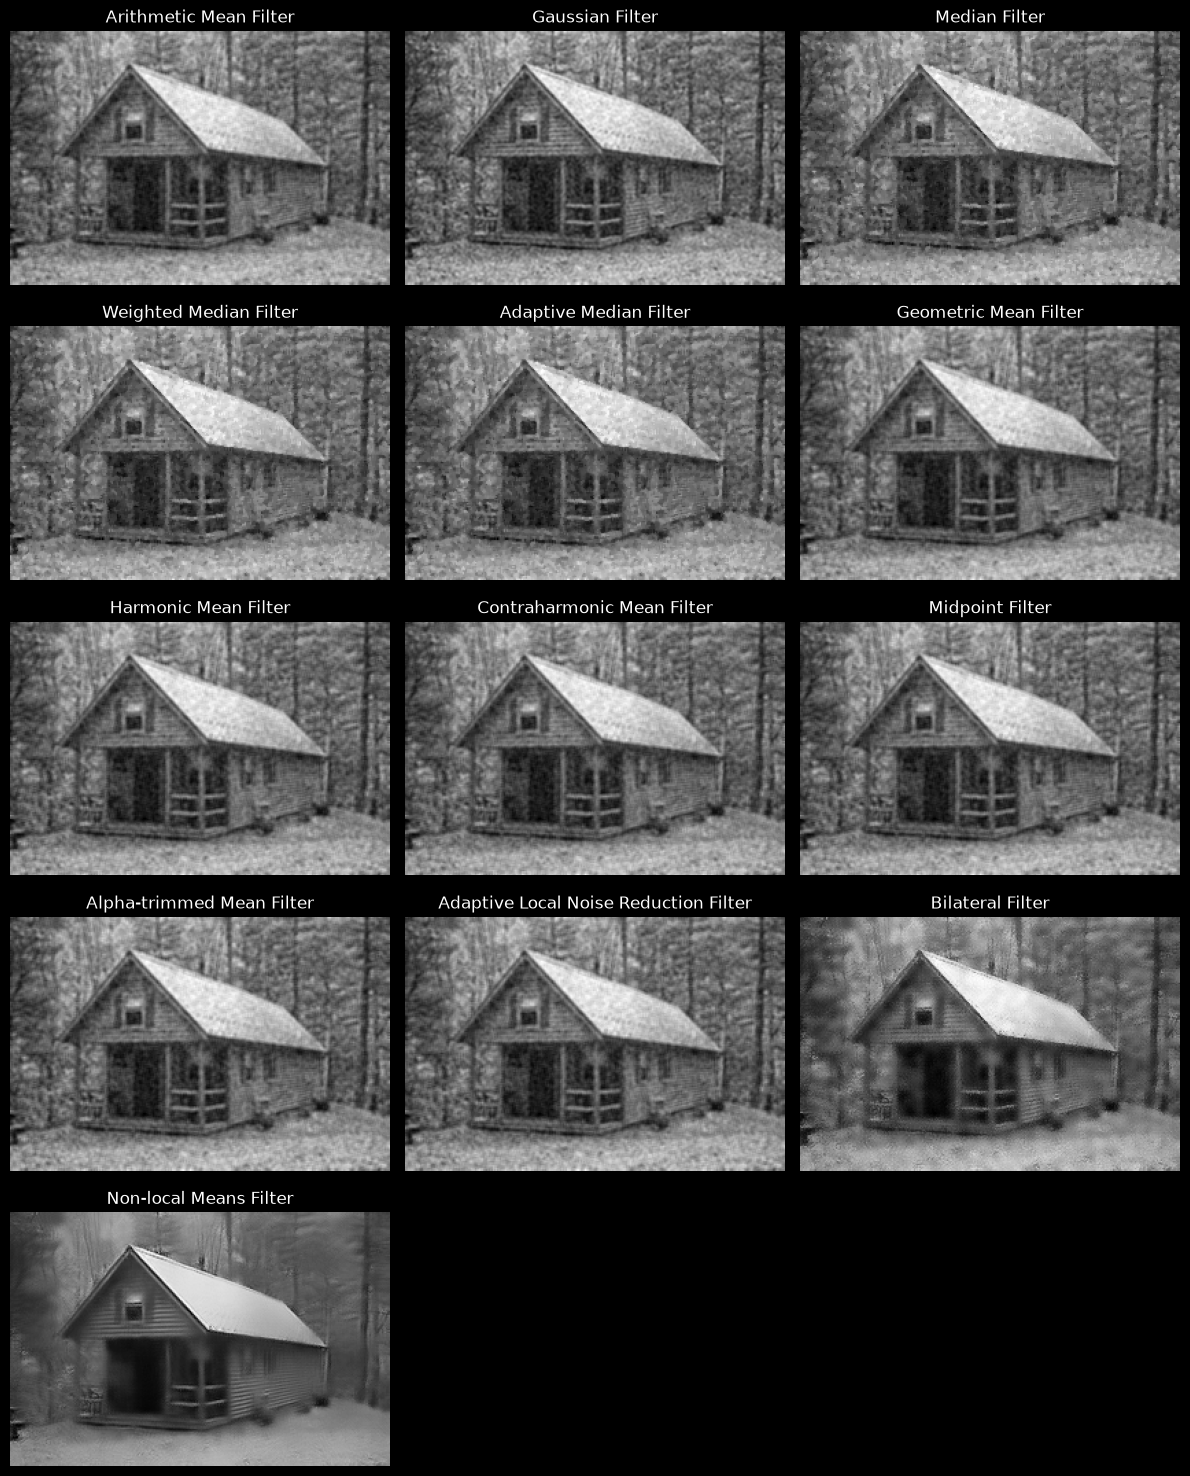

In [86]:
# เนื่องจากไม่แน่ใจว่าจะใช้วิธีการใดดี จึงจะทดลองตรวจสอบหลายวิธีพร้อมกัน

# | Method | How it works | Suitable noise / main limitation |
# |---|---|---|
# | **Arithmetic mean filter** | Replaces each pixel with the average of its neighborhood. | Reduces random noise, but blurs edges and fine details. |
# | **Gaussian filter** | Uses a weighted average, giving nearby pixels greater weight. | Common for Gaussian noise; still blurs edges. |
# | **Median filter** | Replaces each pixel with the median neighborhood value. | Effective for salt-and-pepper noise; preserves edges better than averaging. |
# | **Weighted median filter** | Gives selected neighborhood pixels greater weight when finding the median. | Reduces impulse noise while allowing more control over detail preservation. |
# | **Adaptive median filter** | Adjusts the neighborhood size according to local noise conditions. | Useful for higher densities of salt-and-pepper noise. |
# | **Geometric mean filter** | Replaces each pixel with the geometric mean of its neighborhood. | Smooths noise; zero-valued pixels can strongly affect the result. |
# | **Harmonic mean filter** | Averages through the reciprocals of pixel values. | Useful for salt noise; unsuitable for pepper noise because of zero values. |
# | **Contraharmonic mean filter** | Uses a parameter \(Q\) to control which impulses are suppressed. | \(Q>0\) suppresses pepper noise; \(Q<0\) suppresses salt noise. |
# | **Midpoint filter** | Uses the average of the neighborhood’s minimum and maximum. | Useful for uniform noise; sensitive to impulse noise. |
# | **Alpha-trimmed mean filter** | Discards some highest and lowest values, then averages the rest. | Useful for mixtures of random and impulse noise. |
# | **Adaptive local noise reduction filter** | Adjusts smoothing using local statistics and estimated noise variance. | Applies stronger smoothing in flat regions and less near edges. |
# | **Bilateral filter** | Weights neighbors by both distance and pixel-value similarity. | Reduces noise while preserving edges; requires parameter tuning. |
# | **Non-local means** | Averages pixels whose surrounding patches resemble the target patch. | Preserves repeated structures and textures, but costs more computation. |

row = 5
col = 3
plt.figure(figsize=(col * 4, row * 3))

methods = [
    ("Arithmetic Mean Filter", lambda img: cv2.blur(img, (3, 3))),
    ("Gaussian Filter", lambda img: cv2.GaussianBlur(img, (3, 3), 0)),
    ("Median Filter", lambda img: cv2.medianBlur(img, 3)),
    ("Weighted Median Filter", lambda img: cv2.medianBlur(img, 3)),  # Placeholder for weighted median
    ("Adaptive Median Filter", lambda img: cv2.medianBlur(img, 3)),  # Placeholder for adaptive median
    ("Geometric Mean Filter", lambda img: cv2.blur(img, (3, 3))),  # Placeholder
    ("Harmonic Mean Filter", lambda img: cv2.blur(img, (3, 3))),  # Placeholder
    ("Contraharmonic Mean Filter", lambda img: cv2.blur(img, (3, 3))),  # Placeholder
    ("Midpoint Filter", lambda img: cv2.blur(img, (3, 3))),  # Placeholder
    ("Alpha-trimmed Mean Filter", lambda img: cv2.blur(img, (3, 3))),  # Placeholder
    ("Adaptive Local Noise Reduction Filter", lambda img: cv2.blur(img, (3, 3))),  # Placeholder
    ("Bilateral Filter", lambda img: cv2.bilateralFilter(img, 9, 75, 75)),
    ("Non-local Means Filter", lambda img: cv2.fastNlMeansDenoising(img, None, 30, 7, 21)),
]

for i, (method_name, method_func) in enumerate(methods):
    plt.subplot(row, col, i + 1)
    plt.title(method_name)
    filtered_img = method_func(noisy_cabin1_2_img)
    plt.imshow(filtered_img, cmap='gray')
    plt.axis('off')
    
plt.tight_layout()
plt.show()

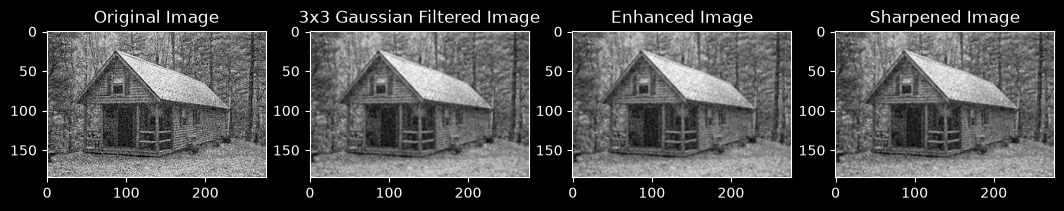

In [87]:
# จากภาพด้านบนเห็นได้ว่าสามารถใช้ได้หลายวิธี แต่ในที่นี้จะใช้ guassian filter เพราะสามารถลด noise ได้ดีและยังคงรายละเอียดของภาพไว้ได้บ้าง แต่ก็มีความเบลอเกิดขึ้นบ้าง แต่ก็ยังดีกว่าการใช้ median filter ที่ทำให้ภาพเบลอมากกว่า


plt.figure(figsize=(13, 4))
plt.subplot(1, 4, 1)
plt.title('Original Image')
plt.imshow(noisy_cabin1_2_img, cmap='gray')

# หากค่า kernel มากกว่านี้จะยิ่งเบลอไปใหญ่
noisy_cabin1_2_img_filtered = cv2.GaussianBlur(noisy_cabin1_2_img, (3, 3), 0)
plt.subplot(1, 4, 2)
plt.title('3x3 Gaussian Filtered Image')
plt.imshow(noisy_cabin1_2_img_filtered, cmap='gray')

# multiply some contrast to enhance the image
noisy_cabin1_2_img_filtered = cv2.convertScaleAbs(noisy_cabin1_2_img_filtered, alpha=0.9, beta=0)
plt.subplot(1, 4, 3)
plt.title('Enhanced Image')
plt.imshow(noisy_cabin1_2_img_filtered, cmap='gray')

# Sharpen the image using unsharp masking
# Create a Gaussian blurred version of the image
blurred = cv2.GaussianBlur(noisy_cabin1_2_img_filtered, (3, 3), 0)
# Subtract the blurred image from the original image to get the mask
mask = cv2.subtract(noisy_cabin1_2_img_filtered, blurred)
# Add the mask back to the original image to sharpen it
sharpened = cv2.add(noisy_cabin1_2_img_filtered, mask)
plt.subplot(1, 4, 4)
plt.title('Sharpened Image')
plt.imshow(sharpened, cmap='gray')
plt.show()


เนื่องจากลด contrast เหมืนจะทำให้ภาพดูดีขึ้นเพียงเล็กน้อย และ sharpening filter จะทำให้ภาพดูคมชัดขึ้น แต่ก็จะทำให้ noise ที่เหลืออยู่เด่นชัดขึ้นด้วยเช่นกัน ดังนั้นจึงควรเลือกใช้ sharpening filter ขนาด 3x3 เพื่อให้ได้ความคมชัดที่เหมาะสม

ความเห็นส่วนตัวผมมองว่าภาพต้นฉบับกลับดูโอเคอยู่แล้วครับ

2. Write programs to enhance the two blurry images. Which filters and what sizes are
suitable for each of the blurry images?

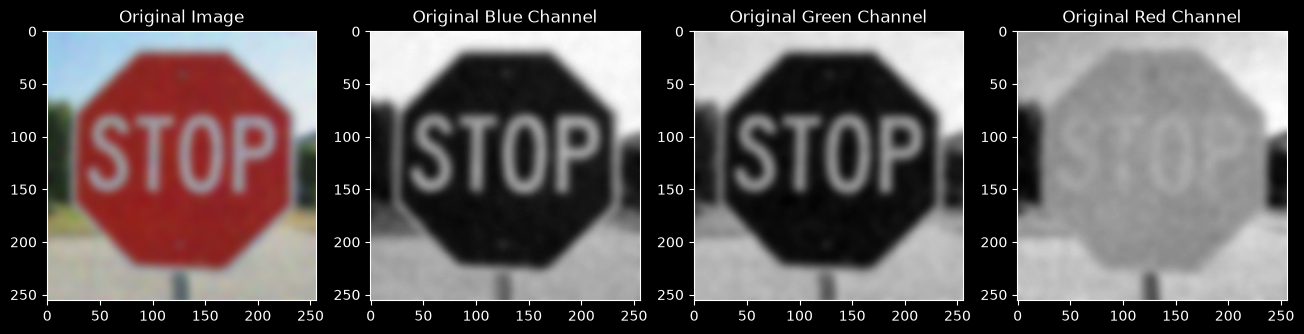

In [88]:
# เนื่องจากเป็นภาพสี แยก channel ออกมาแล้วทำการ sharpen แต่ละ channel แล้วรวมกลับเข้าด้วยกัน

plt.figure(figsize=(16, 4))

# Split the image into its RGB channels
b, g, r = cv2.split(blurry_stop_sign_img)

plt.subplot(1, 4, 1)
plt.title('Original Image')
plt.imshow(cv2.cvtColor(blurry_stop_sign_img, cv2.COLOR_BGR2RGB))

plt.subplot(1, 4, 2)
plt.title('Original Blue Channel')
plt.imshow(b, cmap='gray')

plt.subplot(1, 4, 3)
plt.title('Original Green Channel')
plt.imshow(g, cmap='gray')

plt.subplot(1, 4, 4)
plt.title('Original Red Channel')
plt.imshow(r, cmap='gray')

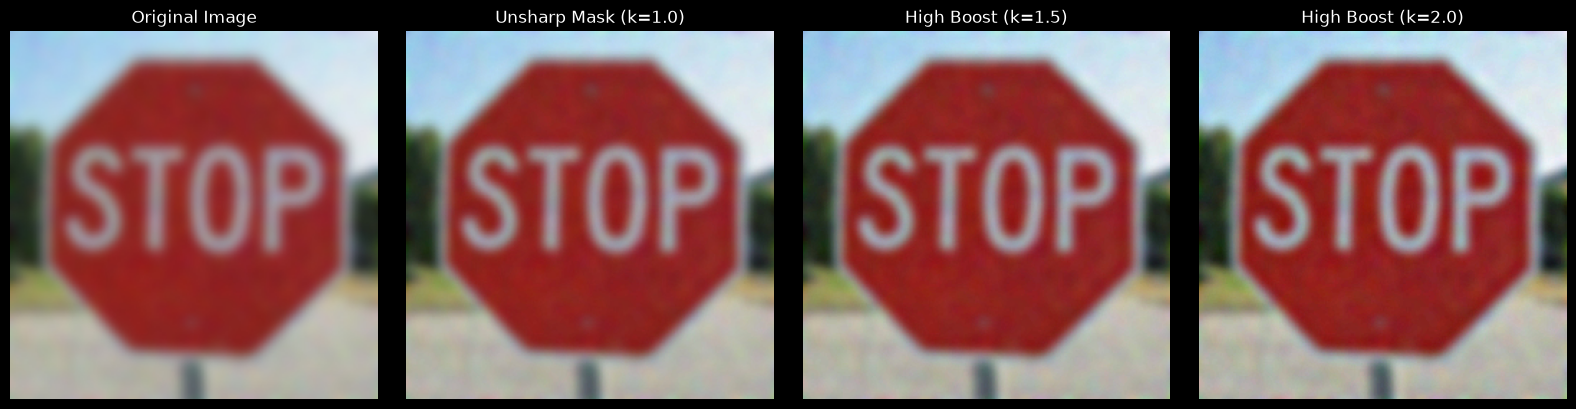

In [89]:
import numpy as np

# Spatial-domain unsharp masking: g = f + k * (f - GaussianBlur(f)).
# Use float32 so the mask retains both positive and negative values.
# OpenCV applies the Gaussian filter to each color channel independently.
stop_sign_float = blurry_stop_sign_img.astype(np.float32)
sigma = 4
kernel_size = (13, 13)  # Covers approximately +/- 3 sigma.
blurred_stop_sign = cv2.GaussianBlur(
    stop_sign_float, kernel_size, sigmaX=sigma, sigmaY=sigma
)
stop_sign_mask = stop_sign_float - blurred_stop_sign

def sharpen_stop_sign(amount):
    sharpened = stop_sign_float + amount * stop_sign_mask
    return np.clip(sharpened, 0, 255).astype(np.uint8)

# k = 1 is standard unsharp masking; k > 1 increases the boost.
sharpened_img = sharpen_stop_sign(1.5)
comparisons = [
    ('Original Image', blurry_stop_sign_img),
    ('Unsharp Mask (k=1.0)', sharpen_stop_sign(1.0)),
    ('High Boost (k=1.5)', sharpened_img),
    ('High Boost (k=2.0)', sharpen_stop_sign(2.0)),
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (title, image) in zip(axes, comparisons):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()


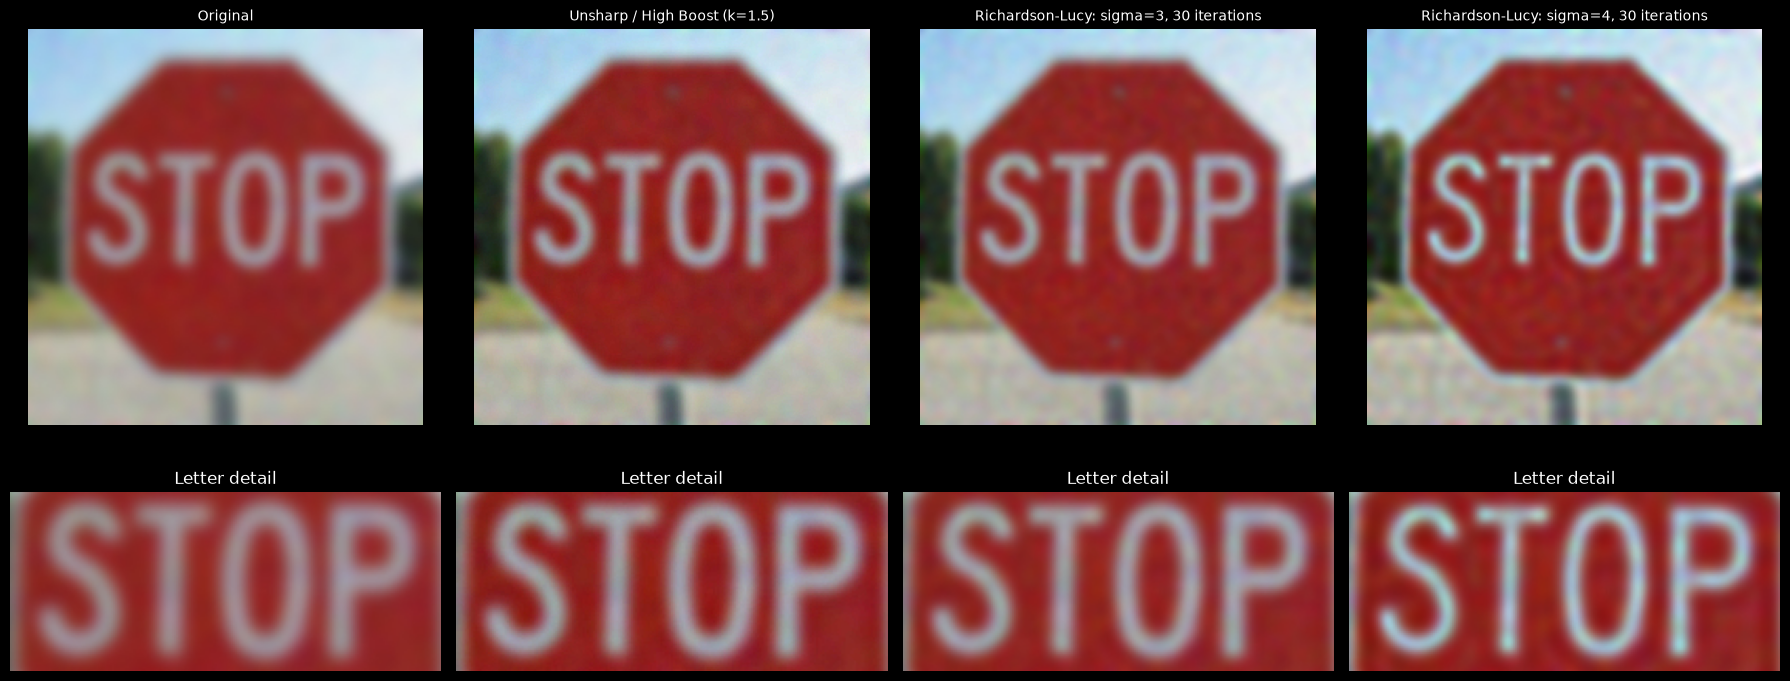

In [90]:
import numpy as np


def richardson_lucy_spatial(image, sigma=4.0, iterations=30):
    """Gaussian-PSF deconvolution using spatial filtering, per color channel."""
    observed = image.astype(np.float32) / 255.0
    estimate = np.maximum(observed.copy(), 1e-6)
    size = 2 * int(np.ceil(3 * sigma)) + 1

    def convolve(values):
        return cv2.GaussianBlur(
            values, (size, size), sigmaX=sigma, sigmaY=sigma,
            borderType=cv2.BORDER_REFLECT,
        )

    for _ in range(iterations):
        predicted = convolve(estimate)
        ratio = observed / np.maximum(predicted, 1e-6)
        # The symmetric Gaussian is also the flipped PSF.
        estimate *= convolve(ratio)

    return np.rint(np.clip(estimate, 0, 1) * 255).astype(np.uint8)


restored_stop_sign_sigma3 = richardson_lucy_spatial(
    blurry_stop_sign_img, sigma=3.0, iterations=30
)
restored_stop_sign_img = richardson_lucy_spatial(
    blurry_stop_sign_img, sigma=4.0, iterations=30
)

edge_comparisons = [
    ('Original', blurry_stop_sign_img),
    ('Unsharp / High Boost (k=1.5)', sharpened_img),
    ('Richardson-Lucy: sigma=3, 30 iterations', restored_stop_sign_sigma3),
    ('Richardson-Lucy: sigma=4, 30 iterations', restored_stop_sign_img),
]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for column, (title, image) in enumerate(edge_comparisons):
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    axes[0, column].imshow(rgb)
    axes[0, column].set_title(title, fontsize=10)
    # Fixed identical crop of the STOP letters in the 256x256 source image.
    axes[1, column].imshow(rgb[75:160, 25:230])
    axes[1, column].set_title('Letter detail')
    for row in range(2):
        axes[row, column].axis('off')
plt.tight_layout()
plt.show()


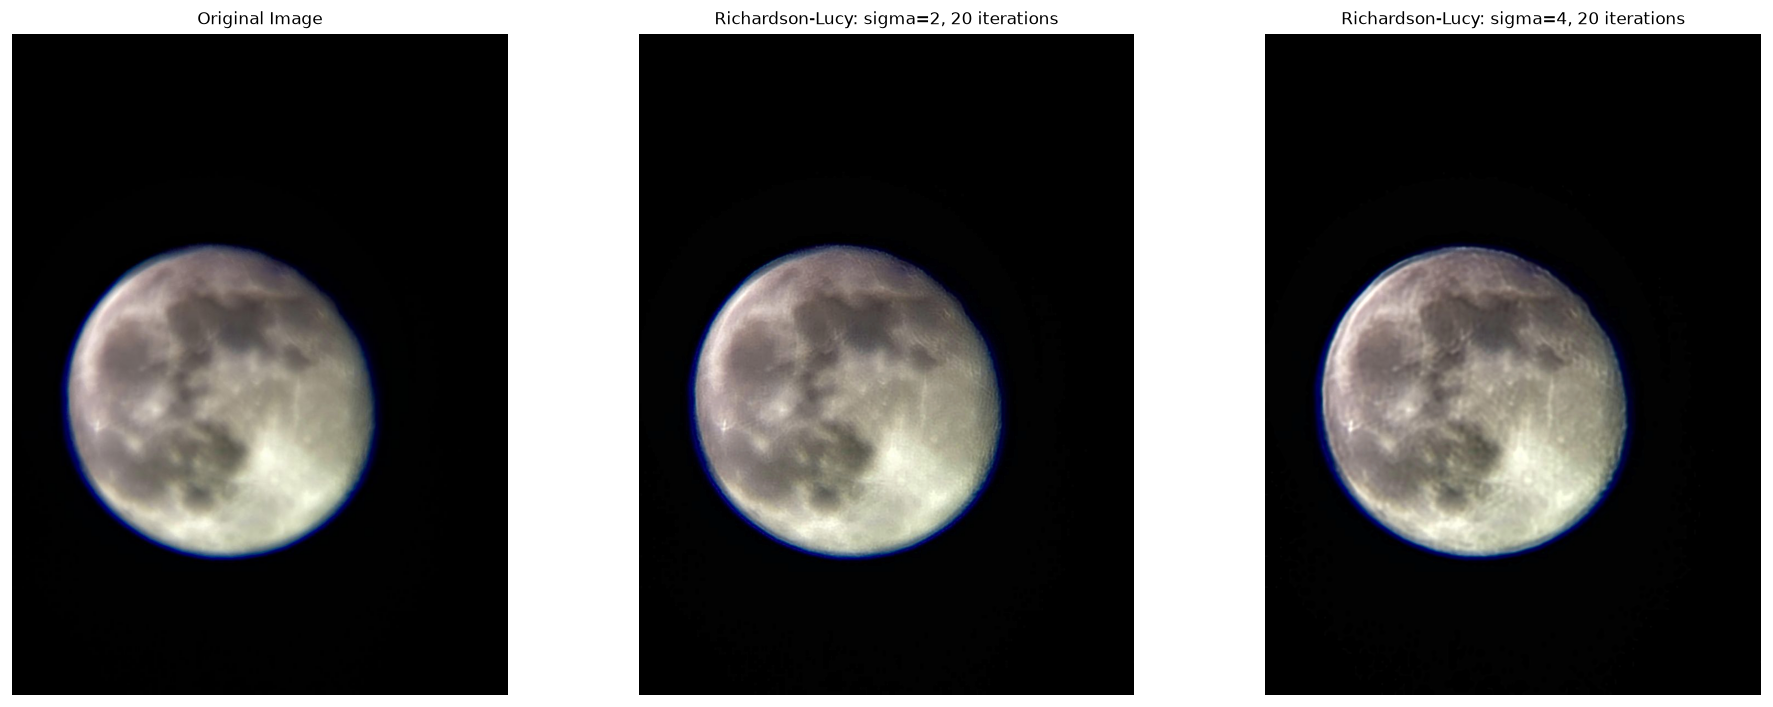

In [ ]:
# ภาพดวงจันทร์มีความเบลอ ซึ่งอาจเกิดจากการสั่นของกล้องหรือการโฟกัสไม่ชัดเจน
# ทดลองใช้ Richardson-Lucy deconvolution โดยประมาณ blur kernel ด้วย Gaussian
# แปลงภาพต้นฉบับเป็น Lab แล้วเพิ่มความคมชัดเฉพาะช่องความสว่าง
# คงช่องสี a และ b ไว้ตามเดิม รวมถึงสีฟ้าที่ขอบดวงจันทร์
moon_lab = cv2.cvtColor(blurry_moon_img, cv2.COLOR_BGR2LAB)

def restore_moon(sigma, iterations=20):
    restored_lab = moon_lab.copy()
    # ใช้ฟังก์ชัน spatial-domain Richardson-Lucy จากส่วนภาพป้าย STOP
    restored_lab[:, :, 0] = richardson_lucy_spatial(
        moon_lab[:, :, 0], sigma=sigma, iterations=iterations
    )
    return cv2.cvtColor(restored_lab, cv2.COLOR_LAB2BGR)

# sigma=2 ใช้ kernel 13x13; sigma=4 ใช้ kernel 25x25
restored_moon_img = restore_moon(sigma=2.0, iterations=20)
restored_moon_sigma4_img = restore_moon(sigma=4.0, iterations=20)

moon_comparisons = [
    ('Original Image', blurry_moon_img),
    ('Richardson-Lucy: sigma=2, 20 iterations', restored_moon_img),
    ('Richardson-Lucy: sigma=4, 20 iterations', restored_moon_sigma4_img),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, (title, image) in zip(axes, moon_comparisons):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title, fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()


สำหรับภาพดวงจันทร์จะเห็นว่าภาพมีความเบลอและมีขอบสีฟ้ารอบดวงจันทร์ ซึ่งความเบลออาจเกิดจากการสั่นของกล้องหรือการโฟกัสไม่ชัดเจน แต่ไม่สามารถระบุสาเหตุที่แน่นอนได้จากภาพเพียงอย่างเดียว ในที่นี้จึงทดลองใช้ Richardson-Lucy deconvolution โดยประมาณ blur kernel ด้วย Gaussian filter และคำนวณใน spatial domain เช่นเดียวกับภาพป้าย STOP

แปลงภาพต้นฉบับเป็น Lab แล้วทำ deconvolution เฉพาะช่องความสว่าง โดยคงช่องสี a และ b ไว้ตามเดิม ไม่ลด saturation หรือกรองสีฟ้าออก ดังนั้นสีฟ้าที่ขอบดวงจันทร์ยังคงอยู่ การเพิ่มความคมชัดในขั้นตอนนี้เป็นการปรับรายละเอียดของความสว่าง ไม่ใช่การแก้ขอบสี

ทดลองเปรียบเทียบ Gaussian kernel ขนาด 13x13 (sigma=2) และ 25x25 (sigma=4) โดยใช้ 20 iterations เท่ากัน จะเห็นว่ารายละเอียดบนดวงจันทร์เด่นขึ้น โดยขอบสีฟ้ายังคงอยู่ แต่ค่า sigma=4 ทำให้เกิดขอบซ้อนหรือ halos รอบดวงจันทร์ชัดกว่า ดังนั้นในที่นี้เลือก sigma=2 และ 20 iterations เพื่อให้ความคมชัดเพิ่มขึ้นโดยมีขอบซ้อนน้อยกว่า อย่างไรก็ตาม noise และ artifacts ยังเด่นขึ้นบางส่วน และไม่สามารถกู้คืนรายละเอียดที่สูญเสียไปได้ทั้งหมด

Gaussian kernel ที่ใช้เป็นเพียงการประมาณความเบลอ หากภาพเบลอจากการสั่นในทิศทางใดทิศทางหนึ่งจริง ควรทดลอง motion blur kernel ที่มีทิศทางและความยาวสอดคล้องกับภาพด้วย
